Import the libraries

In [2]:
import os
import warnings
import kagglehub

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    # GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42


Download and load the dataset

In [3]:
path = kagglehub.dataset_download(
    "srisyra02/ecommerce-customer-behavior-dataset"
)

print("Dataset downloaded to:", path)

# Find CSV files
csv_files = [
    file for file in os.listdir(path)
    if file.endswith(".csv")
]

print("Available CSV files:", csv_files)

Dataset downloaded to: /home/drani/.cache/kagglehub/datasets/srisyra02/ecommerce-customer-behavior-dataset/versions/2
Available CSV files: ['eCommerce-dataset.csv']


Load the first csv file

In [4]:
if not csv_files:
    raise FileNotFoundError("No CSV file found.")

df = pd.read_csv(
    os.path.join(path, csv_files[0])
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


Data undertanding

In [5]:
print("Shape:", df.shape)

print("\nFirst five records:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nColumn names:")
print(df.columns.tolist())

Shape: (50000, 25)

First five records:


,Age,Gender,Country,City,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,...,Email_Open_Rate,Customer_Service_Calls,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Payment_Method_Diversity,Lifetime_Value,Credit_Balance,Churned,Signup_Quarter
0,43.0,Male,France,Marseille,2.9,14,27.4,6.0,50.6,3.0,...,17.9,9.0,4.0,16.3,20.8,1.0,953.33,2278.0,0,Q1
1,36.0,Male,UK,Manchester,1.6,15,42.7,10.3,37.7,1.0,...,42.8,7.0,3.0,NaN,23.3,3.0,1067.47,3028.0,0,Q4
2,45.0,Female,Canada,Vancouver,2.9,10,24.8,1.6,70.9,1.0,...,0.0,4.0,1.0,NaN,8.8,NaN,1289.75,2317.0,0,Q4
3,56.0,Female,USA,New York,2.6,10,38.4,14.8,41.7,9.0,...,41.4,2.0,5.0,85.9,31.0,3.0,2340.92,2674.0,0,Q1
4,35.0,Male,India,Delhi,3.1,29,51.4,NaN,19.1,9.0,...,37.9,1.0,11.0,83.0,50.4,4.0,3041.29,5354.0,0,Q4



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            47505 non-null  float64
 1   Gender                         50000 non-null  str    
 2   Country                        50000 non-null  str    
 3   City                           50000 non-null  str    
 4   Membership_Years               50000 non-null  float64
 5   Login_Frequency                50000 non-null  int64  
 6   Session_Duration_Avg           46601 non-null  float64
 7   Pages_Per_Session              47000 non-null  float64
 8   Cart_Abandonment_Rate          50000 non-null  float64
 9   Wishlist_Items                 46000 non-null  float64
 10  Total_Purchases                50000 non-null  float64
 11  Average_Order_Value            50000 non-null  float64
 12  Days_Since_Last_Purchase       4700

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,47505.0,NaN,NaN,NaN,37.802968,11.834668,5.0,29.0,38.0,46.0,200.0
Gender,50000,3,Female,25116,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,50000,8,USA,17384,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,50000,40,Houston,3549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Membership_Years,50000.0,NaN,NaN,NaN,2.984009,2.059105,0.1,1.4,2.5,4.0,10.0
Login_Frequency,50000.0,NaN,NaN,NaN,11.62466,7.810657,0.0,6.0,11.0,17.0,46.0
Session_Duration_Avg,46601.0,NaN,NaN,NaN,27.660754,10.871013,1.0,19.7,26.8,34.7,75.6
Pages_Per_Session,47000.0,NaN,NaN,NaN,8.737811,3.77822,1.0,6.0,8.4,11.2,24.1
Cart_Abandonment_Rate,50000.0,NaN,NaN,NaN,57.079973,16.282723,0.0,46.4,58.1,68.7,143.74335
Wishlist_Items,46000.0,NaN,NaN,NaN,4.298391,3.189754,0.0,2.0,4.0,6.0,28.0



Column names:
['Age', 'Gender', 'Country', 'City', 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase', 'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate', 'Customer_Service_Calls', 'Product_Reviews_Written', 'Social_Media_Engagement_Score', 'Mobile_App_Usage', 'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance', 'Churned', 'Signup_Quarter']


Check missing values

In [6]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    )
})

display(
    missing.sort_values(
        "Missing_Percentage",
        ascending=False
    )
)

,Missing_Count,Missing_Percentage
Social_Media_Engagement_Score,6000,12.000
Credit_Balance,5500,11.000
Mobile_App_Usage,5000,10.000
Returns_Rate,4491,8.982
Wishlist_Items,4000,8.000
Product_Reviews_Written,3500,7.000
Discount_Usage_Rate,3500,7.000
Session_Duration_Avg,3399,6.798
Pages_Per_Session,3000,6.000
Days_Since_Last_Purchase,3000,6.000


Check duplicates

In [7]:
print("Duplicate records:", df.duplicated().sum())

Duplicate records: 0


Check the target

In [8]:
print(df["Churned"].value_counts())
print(df["Churned"].value_counts(normalize=True) * 100)

Churned
0    35550
1    14450
Name: count, dtype: int64
Churned
0    71.1
1    28.9
Name: proportion, dtype: float64


### Why do we do this?

* We need to know whether the dataset has missing values.

* Duplicate records can distort our analysis.

* Target distribution tells us whether churn classes are balanced.

* Data types determine how we preprocess individual features.

# Exploratory Data Analysis (EDA)

EDA helps us discover patterns before building machine learning models.

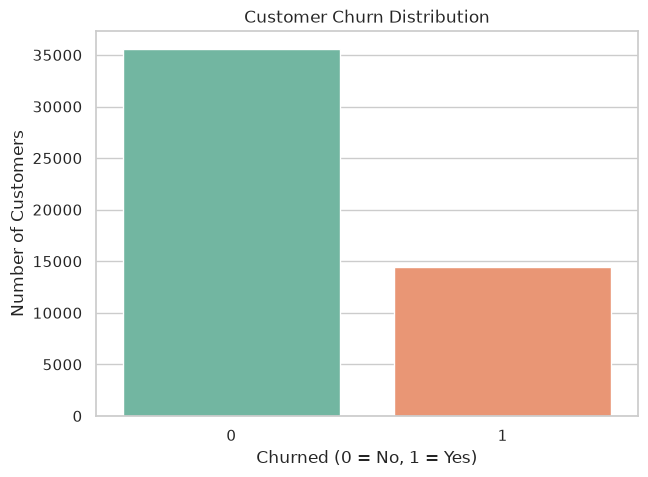

In [9]:
# Churn distribution 
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churned",
    hue="Churned",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churned (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

Churned
0    71.1
1    28.9
Name: proportion, dtype: float64


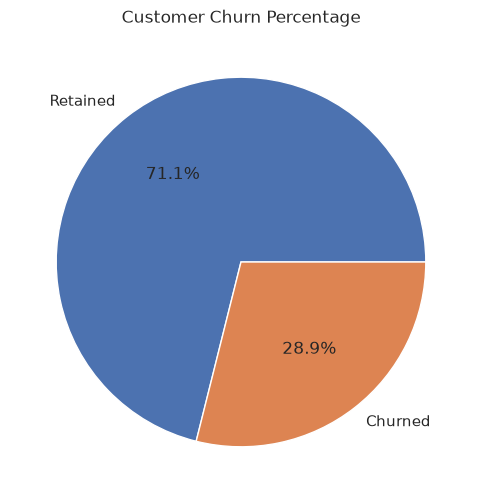

In [10]:
# Churn percentage 

churn_percentage = (
    df["Churned"]
    .value_counts(normalize=True) * 100
)

print(churn_percentage)

churn_percentage.plot(
    kind="pie",
    autopct="%1.1f%%",
    labels=["Retained", "Churned"],
    figsize=(6, 6)
)

plt.title("Customer Churn Percentage")
plt.ylabel("")
plt.show()

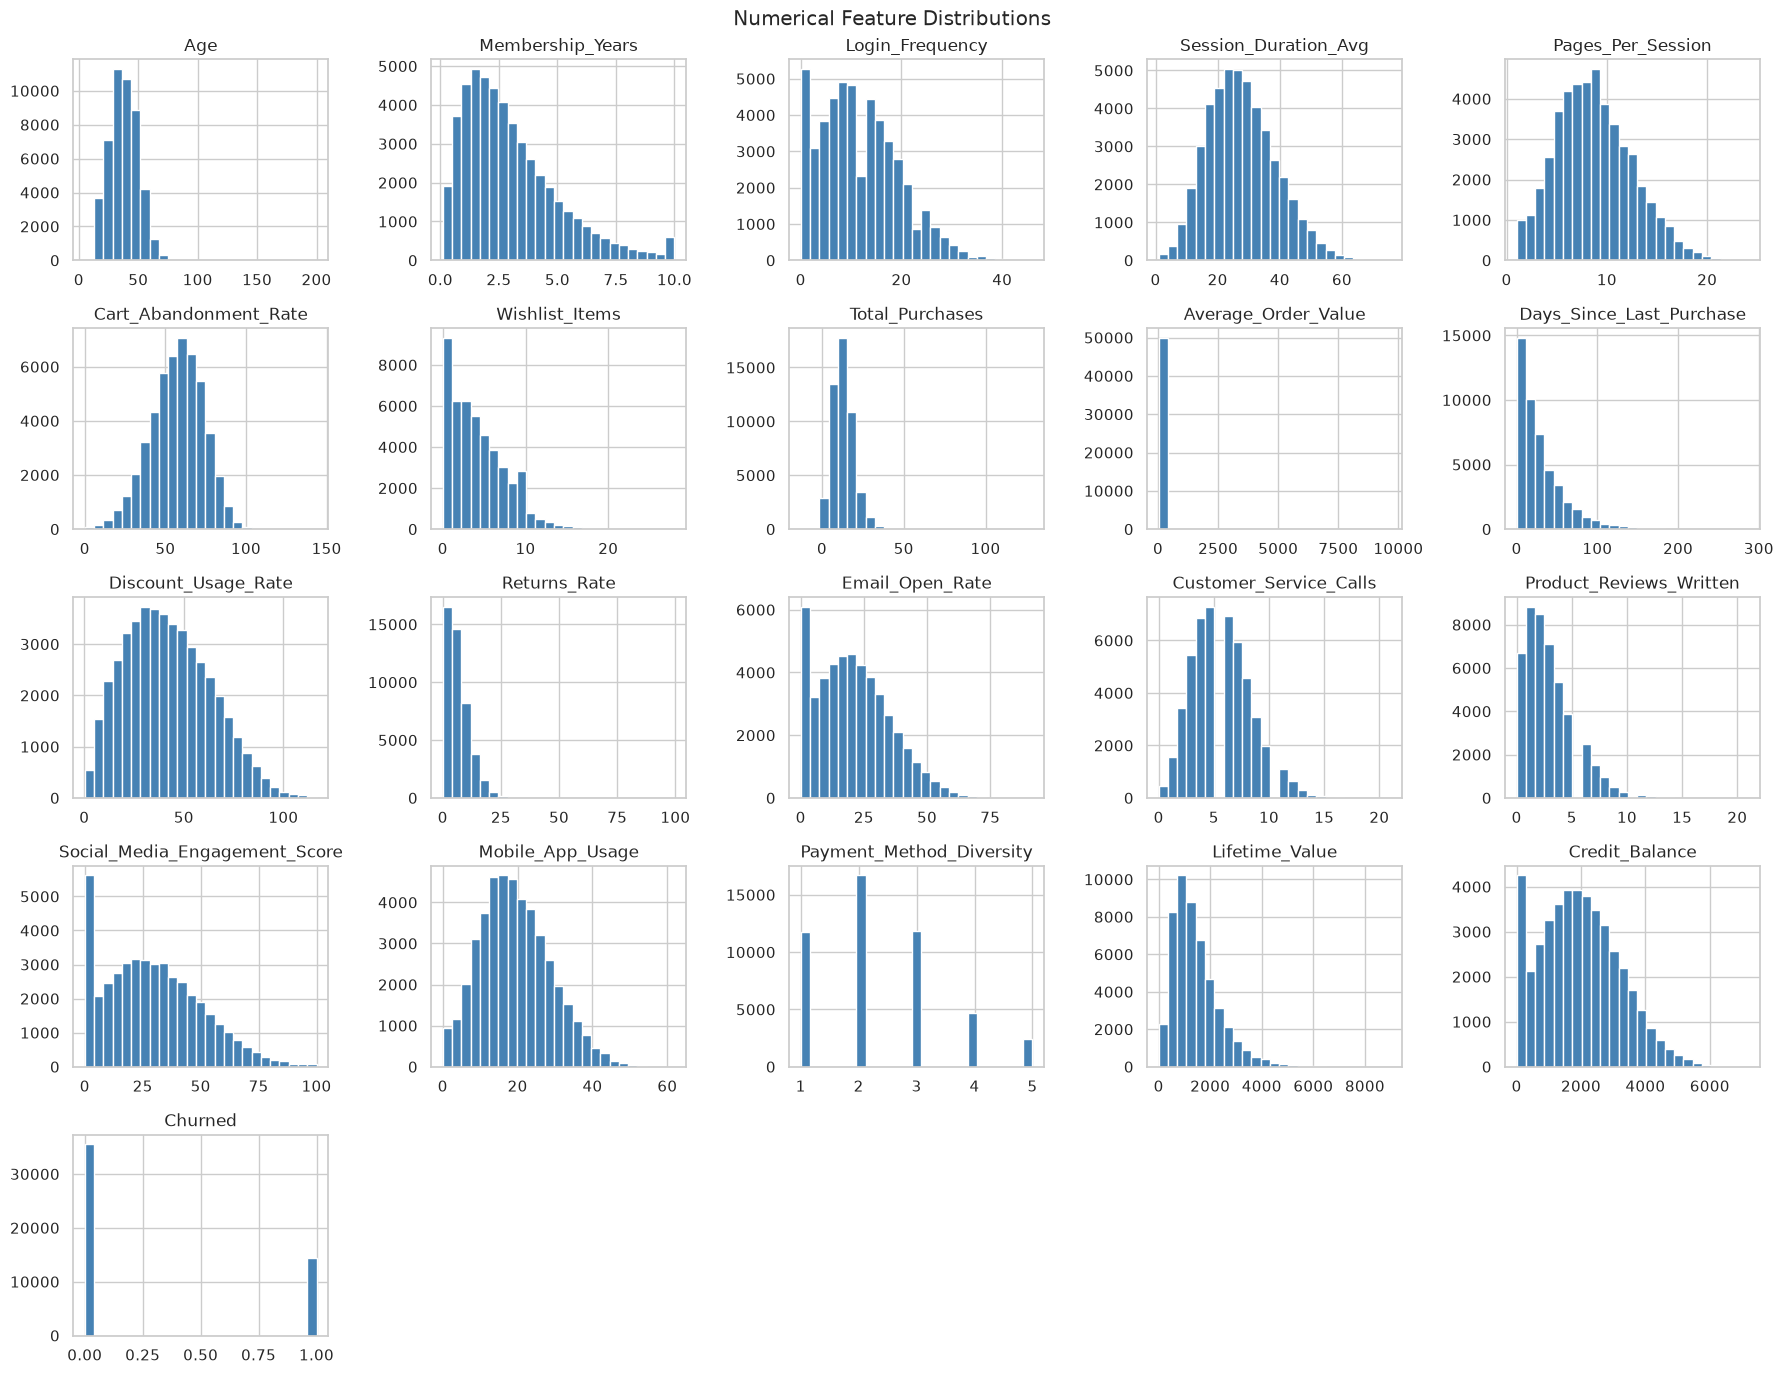

In [11]:
# Numerical feature distribution 
df.hist(
    figsize=(18, 14),
    bins=25,
    color="steelblue"
)

plt.suptitle("Numerical Feature Distributions")
plt.tight_layout()
plt.show()

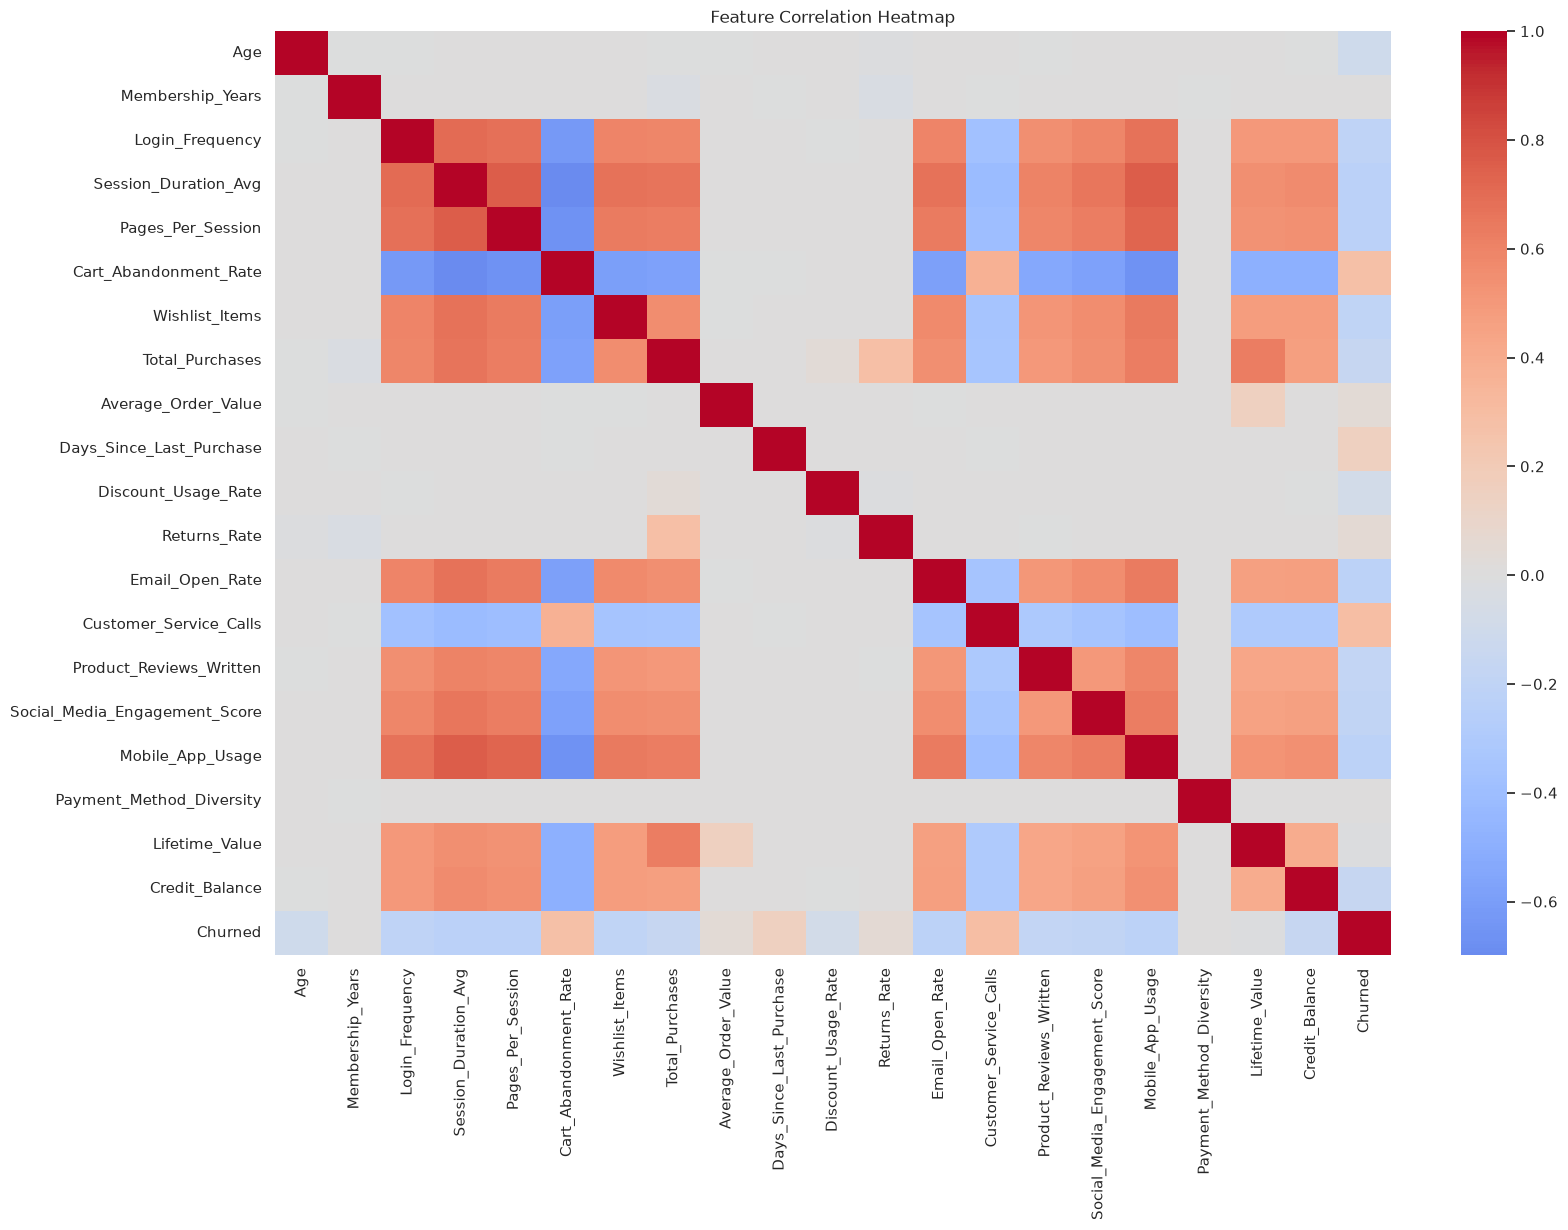

In [12]:
# Correlation analysis 
numeric_df = df.select_dtypes(
    include=np.number
)

plt.figure(figsize=(18, 12))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    annot=False,
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()

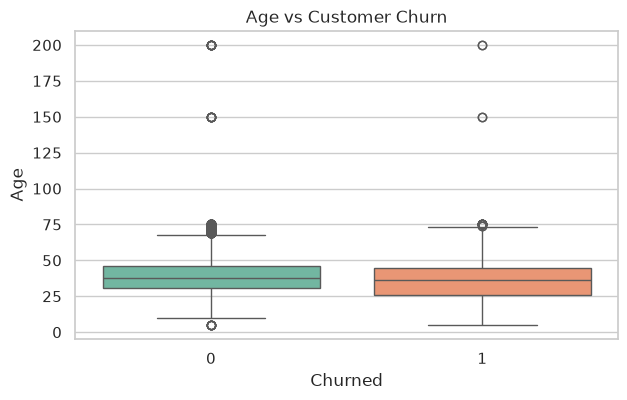

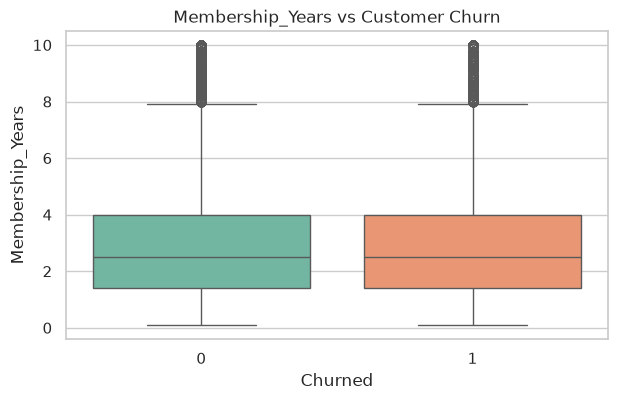

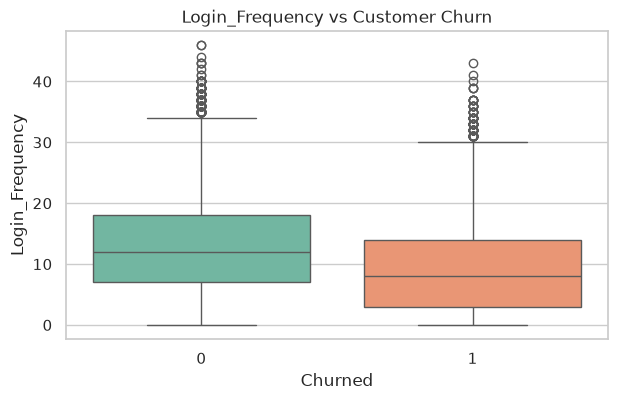

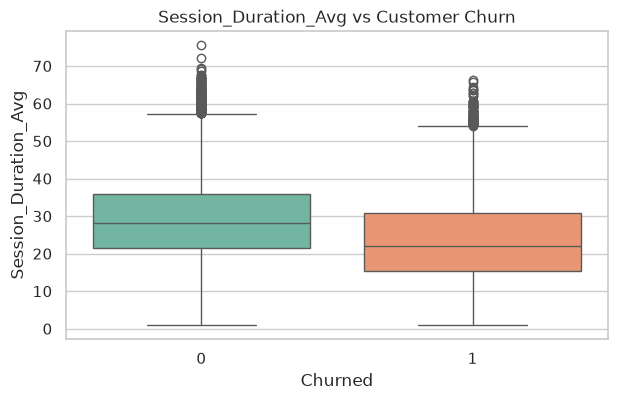

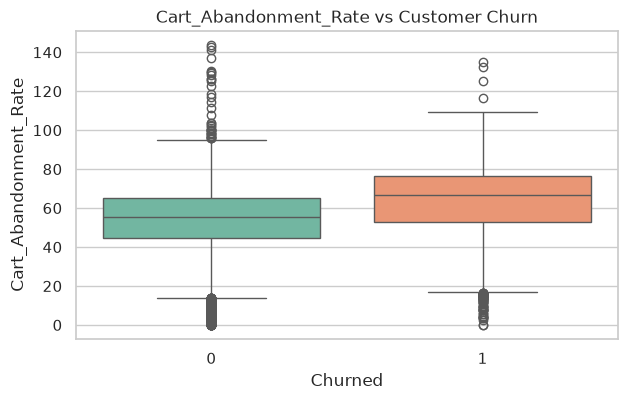

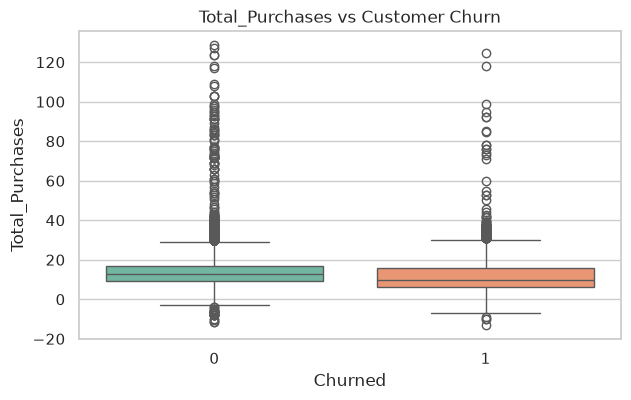

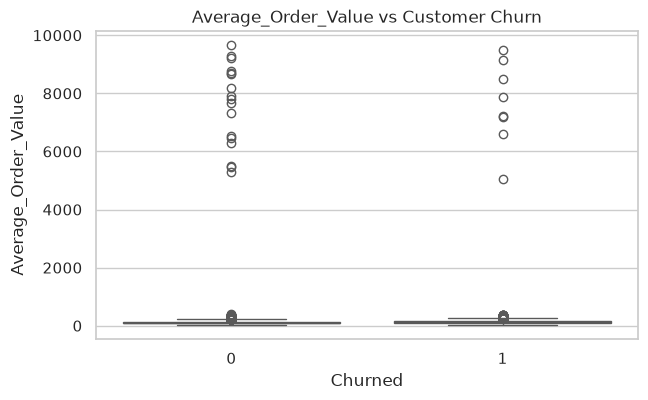

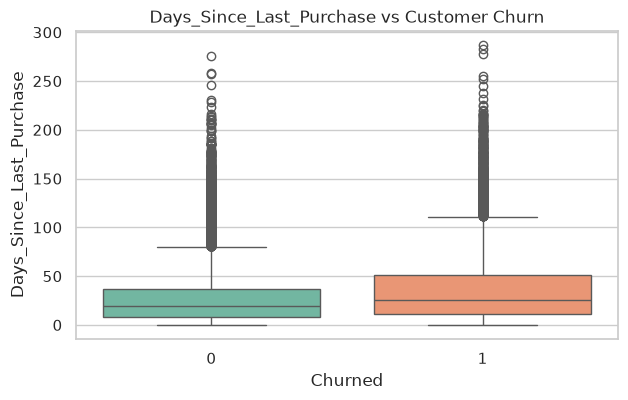

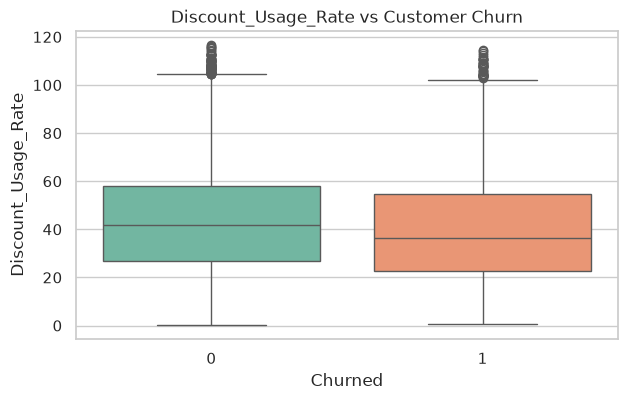

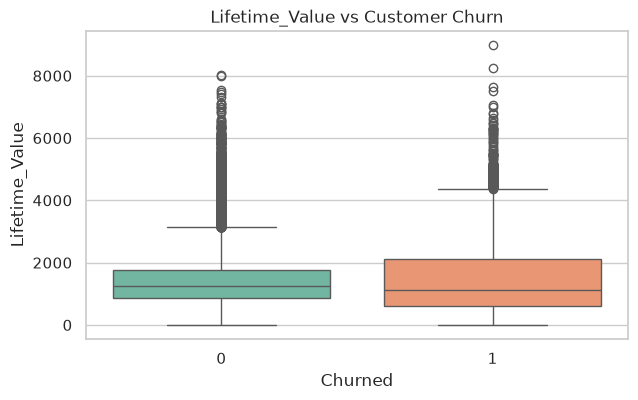

In [13]:
# Understand how features relate to churn 

important_features = [
    "Age",
    "Membership_Years",
    "Login_Frequency",
    "Session_Duration_Avg",
    "Cart_Abandonment_Rate",
    "Total_Purchases",
    "Average_Order_Value",
    "Days_Since_Last_Purchase",
    "Discount_Usage_Rate",
    "Lifetime_Value"
]

available_features = [
    col for col in important_features
    if col in df.columns
]

for feature in available_features:

    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=df,
        x="Churned",
        y=feature,
        hue="Churned",
        palette="Set2",
        legend=False
    )

    plt.title(f"{feature} vs Customer Churn")
    plt.show()

### What should you look for?

For example:

Do customers who log in less frequently churn more?

Does a longer period since the last purchase correspond to more churn?

Are customers with shorter memberships more likely to churn?

Does a higher cart abandonment rate relate to churn?

Remember that correlation and group differences do not automatically establish causation.

#  Data preprocessing

This is one of the most important stages of machine learning.

Our dataset contains two major feature types:

Feature type

Examples

Preprocessing

Numerical

Age, Lifetime_Value

Missing-value imputation and scaling

Categorical

Gender, Country, City

Missing-value imputation and one-hot encoding

 Data preprocessing

In [16]:
# Prepare the target variable 

# Remove records without a target
df = df.dropna(subset=["Churned"]).copy()

# Ensure binary target values
df["Churned"] = pd.to_numeric(
    df["Churned"],
    errors="coerce"
)

df = df.dropna(subset=["Churned"]).copy()

if not set(df["Churned"].unique()).issubset({0, 1}):
    raise ValueError("Churned must contain only 0 and 1.")

df["Churned"] = df["Churned"].astype(int)

In [17]:
# Separate feature and target 

X = df.drop(columns=["Churned"])
y = df["Churned"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (50000, 24)
Target shape: (50000,)


In [18]:
# Identify numerial and categorical features 

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Age', 'Membership_Years', 'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases', 'Average_Order_Value', 'Days_Since_Last_Purchase', 'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate', 'Customer_Service_Calls', 'Product_Reviews_Written', 'Social_Media_Engagement_Score', 'Mobile_App_Usage', 'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance']

Categorical features:
['Gender', 'Country', 'City', 'Signup_Quarter']


In [19]:
# Split the dataset into training and testing sets 

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (40000, 24)
Testing data: (10000, 24)


### Why stratify=y?

It helps maintain approximately the same proportion of churned and retained customers in both sets.

The test set must remain separate from model training and hyperparameter tuning.

# Build preprocessing pipelines
For numerical features:

Replace missing values with the median.

Standardize the values.

For categorical features:

Replace missing values with the most frequent category.

Convert categories into numerical representations using One-Hot Encoding.

In [20]:
# Build preprocessing pipeline 

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [21]:
# Define the models 

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_split=10,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=20,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
}

In [22]:
# Train the models 

trained_models = {}
results = []

for name, model in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)

    # Prediction probabilities
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc
    })

    trained_models[name] = pipeline

    print(f"{name} training completed!")


Training Logistic Regression...
Logistic Regression training completed!

Training Decision Tree...
Decision Tree training completed!

Training Random Forest...
Random Forest training completed!


In [23]:
# Compare model performance 

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.9057,0.8351,0.8394,0.8373,0.9243
1,Decision Tree,0.8743,0.7807,0.7858,0.7832,0.8616
0,Logistic Regression,0.7149,0.5047,0.7308,0.5970,0.7899


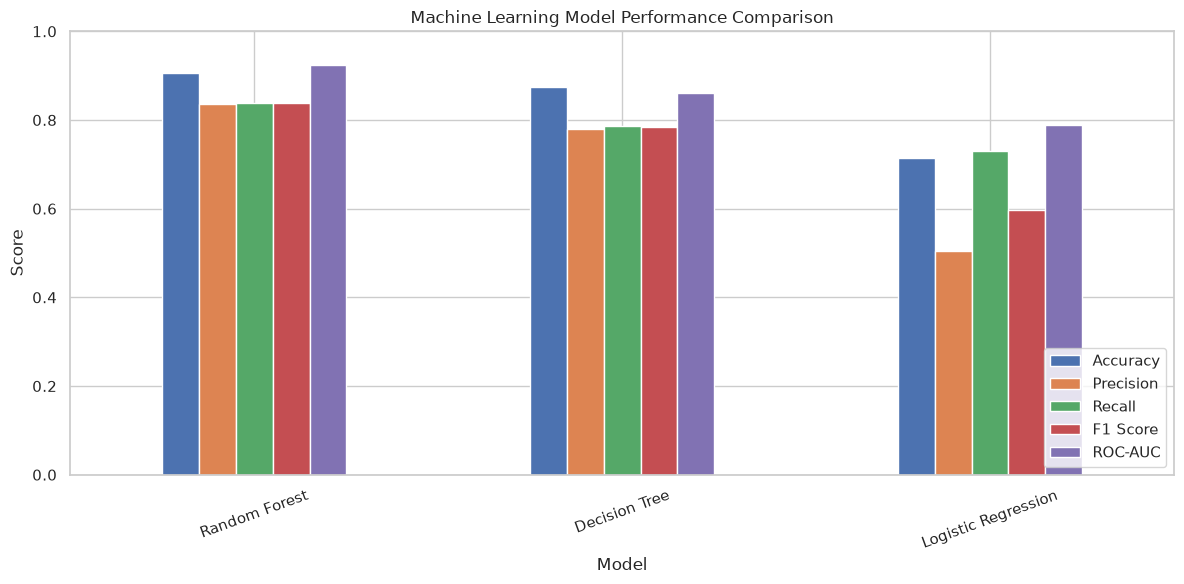

In [24]:
# Visualize the comparison

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [26]:
# Select and tune the best model 

best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best model:", best_model_name)

Best model: Random Forest


### Hyperparameters are settings we choose before training a model.

For example, in Random Forest:

n_estimators: Number of decision trees.

max_depth: Maximum tree depth.

min_samples_split: Minimum observations required to split a node.

min_samples_leaf: Minimum observations in a leaf.

We can tune the Random Forest using cross-validation.

In [28]:
# Hyperparameter tuning 

from sklearn.model_selection import RandomizedSearchCV

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        )
    ]
)

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [10, 20, 30, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=8,
    scoring="f1",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print("Best cross-validation F1:")
print(search.best_score_)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters:
{'classifier__n_estimators': 300, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_depth': None}
Best cross-validation F1:
0.8365052854434157


In [29]:
# using the tuned model 
best_model = search.best_estimator_

best_model_name = "Tuned Random Forest"

Model testing and evaluation

In [30]:
# Generate predictions 

y_pred = best_model.predict(X_test)

y_prob = best_model.predict_proba(X_test)[:, 1]

In [31]:
# Calculate evaluation metrics 

print("MODEL:", best_model_name)

print("\nAccuracy:",
      accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred, zero_division=0))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob))

MODEL: Tuned Random Forest

Accuracy: 0.9094
Precision: 0.8520227111426544
Recall: 0.830795847750865
F1 Score: 0.8412754029432375
ROC-AUC: 0.9254101392356396


In [32]:
# Classification report 

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Retained Customer",
            "Churned Customer"
        ]
    )
)

                   precision    recall  f1-score   support

Retained Customer       0.93      0.94      0.94      7110
 Churned Customer       0.85      0.83      0.84      2890

         accuracy                           0.91     10000
        macro avg       0.89      0.89      0.89     10000
     weighted avg       0.91      0.91      0.91     10000



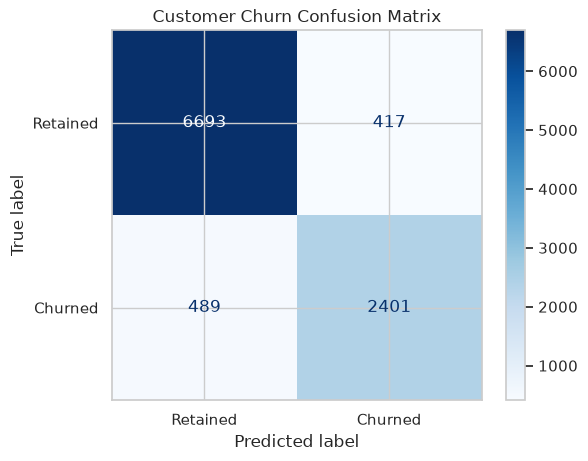

In [33]:
# Confusion matrix 

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Retained",
        "Churned"
    ]
)

disp.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Customer Churn Confusion Matrix")
plt.show()

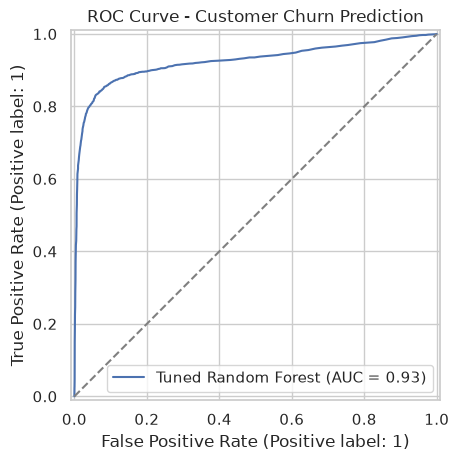

In [34]:
# ROC curve

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name=best_model_name
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray"
)

plt.title("ROC Curve - Customer Churn Prediction")
plt.show()

### Interpretation:

AUC close to 1.0: Excellent discrimination.

AUC around 0.8: Good discrimination.

AUC around 0.5: Performance similar to random ranking.

These are general guidelines, not guaranteed performance thresholds.

# Feature importance
One important question in machine learning is:

Which customer characteristics influence the model's predictions most?

For Random Forest, we can extract feature importance.

In [35]:
# Feature importance 

rf_classifier = best_model.named_steps["classifier"]

feature_names = (
    best_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance.head(20))


,Feature,Importance
13,num__Customer_Service_Calls,0.115660
18,num__Lifetime_Value,0.104572
5,num__Cart_Abandonment_Rate,0.083442
0,num__Age,0.069404
10,num__Discount_Usage_Rate,0.052270
8,num__Average_Order_Value,0.048461
9,num__Days_Since_Last_Purchase,0.048088
7,num__Total_Purchases,0.044673
12,num__Email_Open_Rate,0.043067
4,num__Pages_Per_Session,0.039708


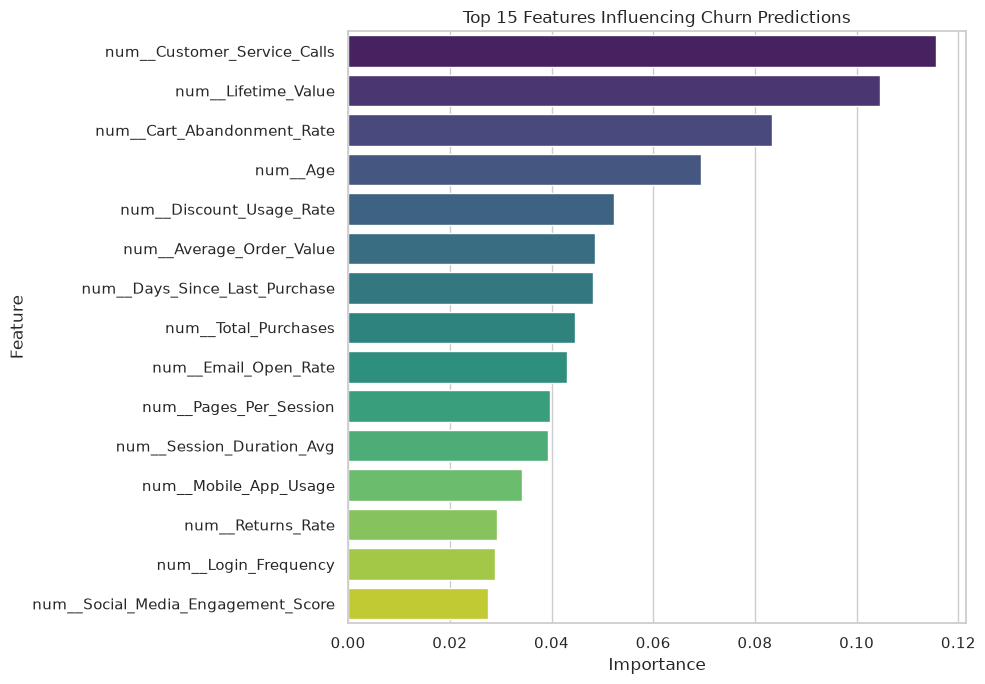

In [36]:
# Visualize the top 15 

top_features = importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 15 Features Influencing Churn Predictions")
plt.tight_layout()
plt.show()


# Choosing a prediction threshold
By default, most classifiers use a probability threshold of 0.5.

For example:

Probability of churn = 0.85 → Predict churn.

Probability of churn = 0.25 → Predict retention.

However, we can change the threshold depending on business priorities.

In [38]:
# Choosing a prediction threshold

threshold = 0.40

y_pred_custom = (
    y_prob >= threshold
).astype(int)

print(
    classification_report(
        y_test,
        y_pred_custom,
        target_names=["Retained", "Churned"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Retained       0.95      0.89      0.91      7110
     Churned       0.76      0.87      0.81      2890

    accuracy                           0.88     10000
   macro avg       0.85      0.88      0.86     10000
weighted avg       0.89      0.88      0.88     10000



### Why use 0.40?

This is just an illustrative alternative. A lower threshold generally identifies more potential churners, but may also increase false positives.

We should choose the threshold based on validation data and the business cost of missed churners versus unnecessary retention campaigns, rather than choosing it arbitrarily.

Save the trained model

In [39]:
import joblib

joblib.dump(
    best_model,
    "customer_churn_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [40]:
# Save the feature names 

joblib.dump(
    X.columns.tolist(),
    "customer_features.pkl"
)

['customer_features.pkl']

In [41]:
# Load and use the trained model 


import joblib

# Load trained model
loaded_model = joblib.load(
    "customer_churn_model.pkl"
)

# Load expected features
expected_features = joblib.load(
    "customer_features.pkl"
)

print("Model loaded successfully!")

Model loaded successfully!


Predict churn for a new customer


In [42]:
# Create an example customer
new_customer = X.iloc[[0]].copy()

# Modify selected values for demonstration
updates = {
    "Age": 28,
    "Membership_Years": 0.5,
    "Login_Frequency": 2,
    "Days_Since_Last_Purchase": 90,
    "Cart_Abandonment_Rate": 80
}

for column, value in updates.items():
    if column in new_customer.columns:
        new_customer.loc[:, column] = value

# Make sure columns are in the expected order
new_customer = new_customer[expected_features]

# Predict
prediction = loaded_model.predict(new_customer)[0]

# Get probability of churn
probability = loaded_model.predict_proba(
    new_customer
)[0][1]

print("Prediction:", prediction)

print(
    "Churn probability:",
    round(probability * 100, 2),
    "%"
)

if prediction == 1:
    print("Customer is predicted to churn.")
else:
    print("Customer is predicted to remain.")

Prediction: 1
Churn probability: 53.67 %
Customer is predicted to churn.
